# 🎛️ Hyperparameter Tuning, Cross-Validation & Pipelines
**Titanic survival prediction, done the professional way: leak-free pipelines, honest validation and efficient search**

**Objective:** Learn how to build a **leak-free scikit-learn Pipeline** for mixed (numeric + categorical + missing) data, how **cross-validation** works and how noisy it is, how to tune hyperparameters with **Grid**, **Random** and **Successive-Halving** search, and how **nested cross-validation** gives an honest performance estimate.
**Tools:** Scikit-learn, Pandas, Matplotlib (+ NumPy, SciPy, joblib)
**Dataset:** Titanic passengers (891 rows): the same data used elsewhere, now treated as a real modelling problem

**Pipeline**
1. Load the data and engineer features (title, family size, cabin flag)
2. Why Pipelines matter: a data-leakage experiment
3. A preprocessing `ColumnTransformer` and baseline models
4. How reliable is cross-validation?
5. Grid vs Random vs Halving search
6. Validation and learning curves
7. Nested cross-validation: the honest estimate
8. Final comparison on the test set, then save the pipeline and predict a passenger

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import randint, uniform

from sklearn.experimental import enable_halving_search_cv  # noqa: F401  (needed for HalvingRandomSearchCV)
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score,
                                     GridSearchCV, RandomizedSearchCV, HalvingRandomSearchCV,
                                     validation_curve, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
os.makedirs("images", exist_ok=True)   # plots are saved here
RANDOM_STATE = 42
print("✅ Libraries imported")

✅ Libraries imported


## 📥 Step 1: Load the Data & Engineer Features

In [2]:
# Auto-detect the Titanic CSV (works on Kaggle via "+ Add Input" AND locally from the data/ folder)
needed = {"Survived", "Pclass", "Name", "Sex", "Age", "SibSp", "Parch", "Fare", "Cabin", "Embarked"}
csv_path = None
for root_dir in ["/kaggle/input", "data"]:
    for dirname, _, filenames in os.walk(root_dir):
        for f in filenames:
            if not f.lower().endswith(".csv") or "cleaned" in f.lower():
                continue
            p = os.path.join(dirname, f)
            try:
                cols = pd.read_csv(p, nrows=1).columns
            except Exception:
                continue
            if needed.issubset(cols) and (csv_path is None or "test" not in f.lower()):
                csv_path = p
if csv_path is None:
    raise FileNotFoundError("Titanic CSV not found. Add a Titanic dataset on Kaggle or place Titanic-Dataset.csv in data/.")

print("Using file:", csv_path)
df = pd.read_csv(csv_path)
print("Shape:", df.shape, "| survival rate:", round(df["Survived"].mean(), 3))
df.head(3)

Using file: data/Titanic-Dataset.csv
Shape: (891, 12) | survival rate: 0.384


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [3]:
def add_features(d):
    # Stateless, row-by-row feature engineering: it uses no statistics of the data set, so it cannot leak.
    d = d.copy()
    title = d["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip().replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    d["Title"] = title.where(title.isin(["Mr", "Miss", "Mrs", "Master"]), "Rare")
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
    d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
    d["HasCabin"] = d["Cabin"].notnull().astype(int)
    return d[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Title", "FamilySize", "IsAlone", "HasCabin"]]

X = add_features(df)
y = df["Survived"]
numeric_cols = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]
categorical_cols = ["Pclass", "Sex", "Embarked", "Title", "IsAlone", "HasCabin"]
X[categorical_cols] = X[categorical_cols].astype(object)

print("Missing values:", X.isnull().sum()[X.isnull().sum() > 0].to_dict())
print("Titles:", X["Title"].value_counts().to_dict())

Missing values: {'Age': 177, 'Embarked': 2}
Titles: {'Mr': 517, 'Miss': 185, 'Mrs': 126, 'Master': 40, 'Rare': 23}


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Survival rate  train: {y_train.mean():.3f}  |  test: {y_test.mean():.3f}")

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (712, 11) | Test: (179, 11)
Survival rate  train: 0.383  |  test: 0.385


### 📝 Observations
- **891 passengers**, 38.4% survived. **Age** has 177 missing values and **Embarked** has 2: they must be imputed *inside* cross-validation, never beforehand
- Engineered `Title` (Mr 517, Miss 185, Mrs 126, Master 40, Rare 23), `FamilySize`, `IsAlone` and `HasCabin`. These are **stateless** (each row is transformed on its own), so computing them before the split is safe
- Stratified split: **712 training / 179 test** passengers, with the same survival rate in both (38.3% train, 38.5% test)

## 🚨 Step 2: Why Pipelines? A Data-Leakage Experiment
Any step that **learns from data** (imputation values, scaling, feature selection, encoding...) must be fitted **only on the training part of each cross-validation fold**.
Doing it on the full data set first lets information from the validation fold leak in.

Here is how dramatic this can be. We create **pure random noise**: 100 samples, 1,000 random features and *random* labels. No model can truly predict this (the honest accuracy is 50%).

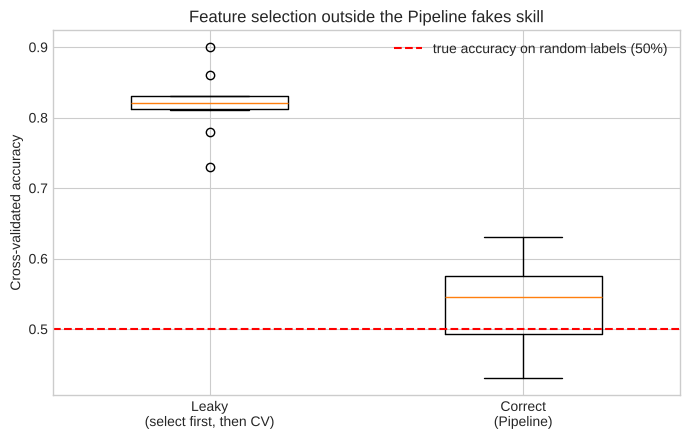

Leaky CV accuracy   : 0.82   <- looks like a great model, but the data is pure noise
Correct CV accuracy : 0.53   <- honest: random guessing


In [5]:
leaky_scores, correct_scores = [], []
for seed in range(10):
    rng = np.random.RandomState(seed)
    A, b = rng.randn(100, 1000), rng.randint(0, 2, 100)

    # WRONG: select the 20 "best" features using ALL labels, then cross-validate
    A_selected = SelectKBest(f_classif, k=20).fit_transform(A, b)
    leaky_scores.append(cross_val_score(LogisticRegression(), A_selected, b, cv=5).mean())

    # RIGHT: the selection is part of the Pipeline, so it is re-fitted inside every training fold
    pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression())
    correct_scores.append(cross_val_score(pipe, A, b, cv=5).mean())

plt.figure(figsize=(7, 4.5))
plt.boxplot([leaky_scores, correct_scores], widths=0.5)
plt.xticks([1, 2], ["Leaky\n(select first, then CV)", "Correct\n(Pipeline)"])
plt.axhline(0.5, color="red", linestyle="--", label="true accuracy on random labels (50%)")
plt.ylabel("Cross-validated accuracy"); plt.title("Feature selection outside the Pipeline fakes skill")
plt.legend()
plt.tight_layout()
plt.savefig("images/01_leakage_experiment.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Leaky CV accuracy   : {np.mean(leaky_scores):.2f}   <- looks like a great model, but the data is pure noise")
print(f"Correct CV accuracy : {np.mean(correct_scores):.2f}   <- honest: random guessing")

### 📝 Observations
- On pure noise the leaky procedure reports **82% accuracy** (averaged over 10 random datasets); the correct Pipeline reports **53%**, i.e. chance
- The cause: choosing the "best" 20 of 1,000 features *using all the labels* lets the model see the validation answers. **Always put every data-dependent step inside the Pipeline** so cross-validation re-fits it per fold
- Everything below uses Pipelines, so the imputers, scalers and encoders are fitted on training folds only

## 🧱 Step 3: A Preprocessing Pipeline & Baseline Models

,CV accuracy (mean),CV accuracy (std)
Logistic Regression,0.8293,0.0262
KNN,0.8055,0.0272
Random Forest,0.8146,0.0253
Gradient Boosting,0.8244,0.0259


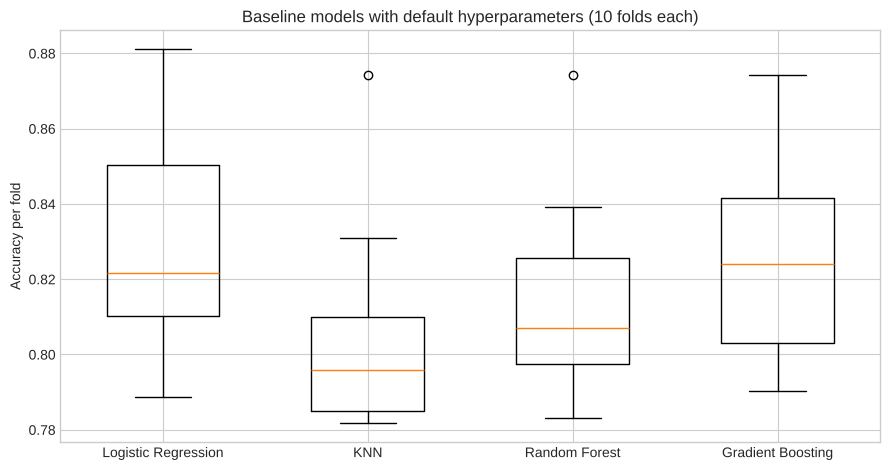

In [6]:
def make_preprocessor(scale):
    numeric = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("num", Pipeline(numeric), numeric_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols),
    ])

# Trees do not need scaling; logistic regression and KNN do
models = {
    "Logistic Regression": make_pipeline(make_preprocessor(True), LogisticRegression(max_iter=2000)),
    "KNN": make_pipeline(make_preprocessor(True), KNeighborsClassifier()),
    "Random Forest": make_pipeline(make_preprocessor(False), RandomForestClassifier(random_state=RANDOM_STATE)),
    "Gradient Boosting": make_pipeline(make_preprocessor(False), GradientBoostingClassifier(random_state=RANDOM_STATE)),
}

# Repeated stratified 5-fold CV (2 repeats = 10 scores per model) is more stable than a single 5-fold run
repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
fold_scores = {name: cross_val_score(m, X_train, y_train, cv=repeated_cv, scoring="accuracy", n_jobs=-1) for name, m in models.items()}

baseline = pd.DataFrame({"CV accuracy (mean)": {k: v.mean() for k, v in fold_scores.items()},
                         "CV accuracy (std)": {k: v.std() for k, v in fold_scores.items()}}).round(4)
display(baseline)

plt.figure(figsize=(9, 4.8))
plt.boxplot(list(fold_scores.values()), widths=0.55)
plt.xticks(range(1, len(fold_scores) + 1), list(fold_scores.keys()))
plt.ylabel("Accuracy per fold"); plt.title("Baseline models with default hyperparameters (10 folds each)")
plt.tight_layout()
plt.savefig("images/02_baseline_models.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (baselines)
| Model (defaults) | CV accuracy | ± std |
|---|---|---|
| **Logistic Regression** | **0.8293** | 0.026 |
| Gradient Boosting | 0.8244 | 0.026 |
| Random Forest | 0.8146 | 0.025 |
| KNN | 0.8055 | 0.027 |

- The spread between models (**2 points**) is smaller than the fold-to-fold noise (**± 2.6 points**): the four models are **statistically almost indistinguishable** on this small dataset
- The simplest model, logistic regression, is already as good as anything else. Tuning must beat this bar to be worth the effort

## 📏 Step 4: How Reliable Is Cross-Validation?
Cross-validation is itself an **estimate with noise**. We look at one 5-fold run of the random forest, then repeat 5-fold CV with 10 different shuffles.

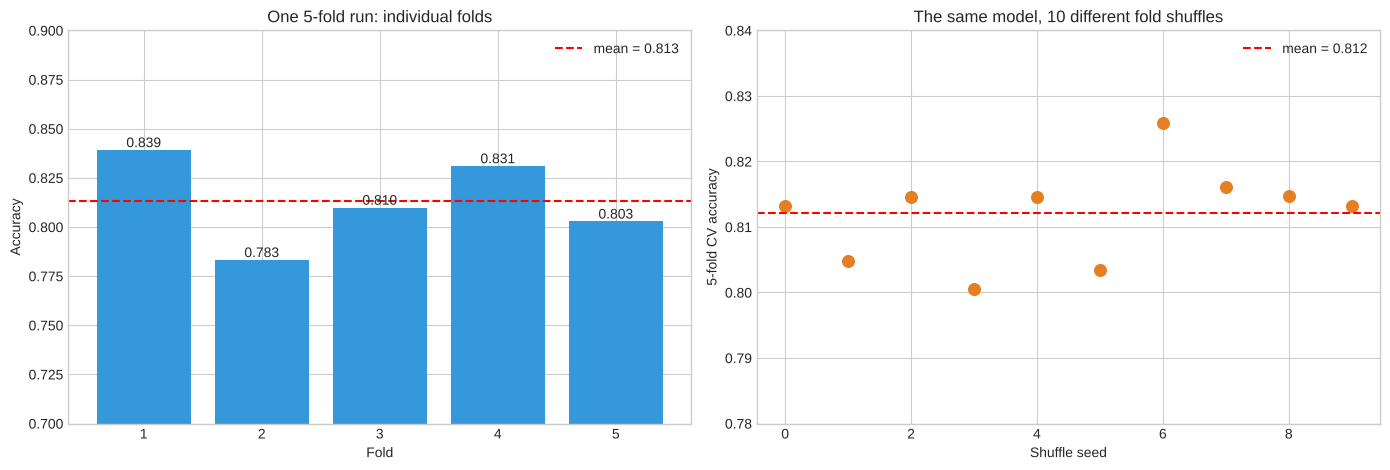

Fold scores: [0.839 0.783 0.81  0.831 0.803] (range 0.783 to 0.839)
10 shuffles: mean 0.8121, std 0.0070, range 0.801 to 0.826


In [7]:
rf_default = models["Random Forest"]
single_run = cross_val_score(rf_default, X_train, y_train, cv=cv5, scoring="accuracy", n_jobs=-1)
default_cv = single_run.mean()

seed_means = [cross_val_score(rf_default, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=s), n_jobs=-1).mean()
              for s in range(10)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(range(1, 6), single_run, color="#3498db")
axes[0].axhline(default_cv, color="red", linestyle="--", label=f"mean = {default_cv:.3f}")
axes[0].set_ylim(0.7, 0.9); axes[0].set_xlabel("Fold"); axes[0].set_ylabel("Accuracy")
axes[0].set_title("One 5-fold run: individual folds"); axes[0].legend()
for i, v in enumerate(single_run, 1):
    axes[0].text(i, v, f"{v:.3f}", ha="center", va="bottom")

axes[1].scatter(range(10), seed_means, color="#e67e22", s=70)
axes[1].axhline(np.mean(seed_means), color="red", linestyle="--", label=f"mean = {np.mean(seed_means):.3f}")
axes[1].set_ylim(0.78, 0.84); axes[1].set_xlabel("Shuffle seed"); axes[1].set_ylabel("5-fold CV accuracy")
axes[1].set_title("The same model, 10 different fold shuffles"); axes[1].legend()
plt.tight_layout()
plt.savefig("images/03_cv_variability.png", dpi=150, bbox_inches="tight")
plt.show()

print("Fold scores:", single_run.round(3), f"(range {single_run.min():.3f} to {single_run.max():.3f})")
print(f"10 shuffles: mean {np.mean(seed_means):.4f}, std {np.std(seed_means):.4f}, range {min(seed_means):.3f} to {max(seed_means):.3f}")

### 📝 Observations (CV noise)
- Within one run, the five folds range from **0.783 to 0.839**: single-fold scores are noisy (± 3 points)
- Averaging the 5 folds helps, but a different shuffle still moves the mean: over 10 shuffles it ranges from **0.801 to 0.826** (std ≈ 0.007)
- ⚠️ So hyperparameter settings that differ by less than about **1 point of CV accuracy** cannot be told apart: they are noise. Use **repeated** CV when you need to rank close candidates

## 🔎 Step 5: Hyperparameter Search: Grid vs Random vs Halving
Hyperparameters (tree depth, number of trees, leaf size...) are settings **chosen before training**. We tune the random forest with three strategies, all using 5-fold CV **on the training set only**:
- **Grid search:** tries every combination of a small grid (36 here). Thorough but explodes with more parameters
- **Random search:** samples combinations from distributions (30 here). Explores more *values* of each parameter for the same budget
- **Successive halving:** starts with many candidates on a *small* data subset and keeps only the best third for each round with 3x more data

In [8]:
rf_pipe = Pipeline([("prep", make_preprocessor(False)), ("clf", RandomForestClassifier(random_state=RANDOM_STATE))])

param_grid = {"clf__n_estimators": [100, 200], "clf__max_depth": [3, 5, None],
              "clf__min_samples_leaf": [1, 3, 5], "clf__max_features": ["sqrt", 0.5]}
param_dist = {"clf__n_estimators": randint(50, 200), "clf__max_depth": [3, 4, 5, 6, 8, 10, None],
              "clf__min_samples_leaf": randint(1, 15), "clf__min_samples_split": randint(2, 20),
              "clf__max_features": ["sqrt", "log2", 0.3, 0.5, 0.8], "clf__bootstrap": [True, False]}

searches = {
    "Grid search":     GridSearchCV(rf_pipe, param_grid, cv=cv5, scoring="accuracy", n_jobs=-1),
    "Random search":   RandomizedSearchCV(rf_pipe, param_dist, n_iter=30, cv=cv5, scoring="accuracy", n_jobs=-1, random_state=RANDOM_STATE),
    "Halving search":  HalvingRandomSearchCV(rf_pipe, param_dist, n_candidates=60, factor=3, cv=cv5, scoring="accuracy", n_jobs=-1, random_state=RANDOM_STATE),
}
rows = []
for name, search in searches.items():
    t0 = time.time(); search.fit(X_train, y_train); elapsed = time.time() - t0
    rows.append({"Method": name, "Candidates tried": len(search.cv_results_["params"]),
                 "Best CV accuracy": search.best_score_, "Test accuracy": search.score(X_test, y_test), "Time (s)": elapsed})
    print(f"{name:15s} best params: { {k.split('__')[1]: v for k, v in search.best_params_.items()} }")
search_table = pd.DataFrame(rows).set_index("Method").round(4)
print()
display(search_table)
print("Halving: candidates per round =", searches["Halving search"].n_candidates_, "| training samples per round =", searches["Halving search"].n_resources_)

Grid search     best params: {'max_depth': 3, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 200}


Random search   best params: {'bootstrap': False, 'max_depth': 4, 'max_features': 'log2', 'min_samples_leaf': 4, 'min_samples_split': 19, 'n_estimators': 93}


Halving search  best params: {'bootstrap': False, 'max_depth': 3, 'max_features': 'log2', 'min_samples_leaf': 4, 'min_samples_split': 13, 'n_estimators': 88}



,Candidates tried,Best CV accuracy,Test accuracy,Time (s)
Method,,,,
Grid search,36,0.8371,0.7933,39.9478
Random search,30,0.8371,0.7933,26.6497
Halving search,90,0.8306,0.7933,65.7676


Halving: candidates per round = [60, 20, 7, 3] | training samples per round = [20, 60, 180, 540]


### 📝 Observations (search methods)
| Method | Candidates tried | Best CV accuracy | Test accuracy |
|---|---|---|---|
| Grid search | 36 | 0.8371 | 0.7933 |
| Random search | 30 | 0.8371 | 0.7933 |
| Halving search | 90 (across 4 rounds) | 0.8306 | 0.7933 |

- All three strategies land on the **same kind of model**: **shallow forests** (`max_depth` 3 to 4, leaves of 1 to 4 samples) with CV accuracy **0.83 to 0.84**. Their exact settings differ a lot, yet the scores are identical: the search landscape is **flat**
- Random search matched the grid with **30 candidates instead of 36**, and it explored many more distinct values (e.g. any number of trees from 50 to 200)
- **Halving** started 60 candidates on only **20 training samples**, kept 20 for **60 samples**, 7 for **180** and the final 3 on all **540** (the full training folds). That is 90 evaluations, but most are cheap. On a dataset this small the overhead of many tiny fits means it is *not* faster (the timings printed above depend on the machine, but in our runs random search was the fastest and halving the slowest). Halving pays off when each fit is expensive (big data, deep models)

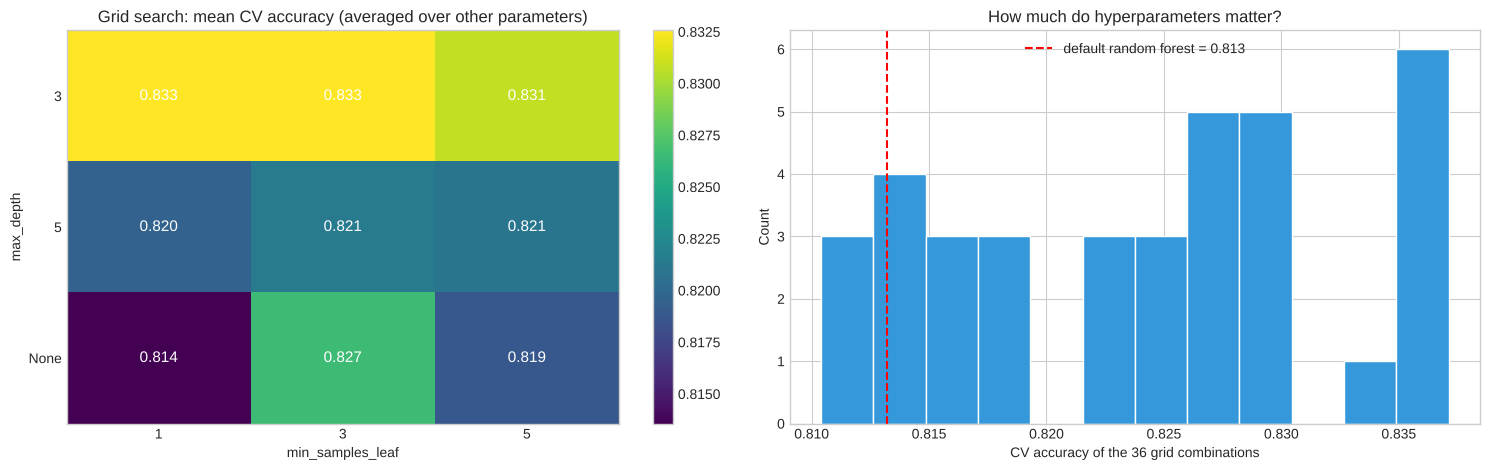

Grid: best 0.8371 | top-10 range 0.8287 to 0.8371 | median 0.8252 | worst 0.8104


In [9]:
cvr = searches["Grid search"].cv_results_
grid_results = pd.DataFrame({"max_depth": [str(p["clf__max_depth"]) for p in cvr["params"]],
                             "min_samples_leaf": [p["clf__min_samples_leaf"] for p in cvr["params"]],
                             "mean_test_score": cvr["mean_test_score"]})
heat = grid_results.pivot_table(index="max_depth", columns="min_samples_leaf", values="mean_test_score", aggfunc="mean").loc[["3", "5", "None"]]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
im = axes[0].imshow(heat.values, cmap="viridis", aspect="auto")
axes[0].set_xticks(range(heat.shape[1])); axes[0].set_xticklabels(heat.columns); axes[0].set_yticks(range(heat.shape[0])); axes[0].set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        axes[0].text(j, i, f"{heat.values[i, j]:.3f}", ha="center", va="center", color="white", fontsize=11)
axes[0].set_xlabel("min_samples_leaf"); axes[0].set_ylabel("max_depth"); axes[0].set_title("Grid search: mean CV accuracy (averaged over other parameters)")
axes[0].grid(False); plt.colorbar(im, ax=axes[0])

axes[1].hist(grid_results["mean_test_score"], bins=12, color="#3498db", edgecolor="white")
axes[1].axvline(default_cv, color="red", linestyle="--", label=f"default random forest = {default_cv:.3f}")
axes[1].set_xlabel("CV accuracy of the 36 grid combinations"); axes[1].set_ylabel("Count")
axes[1].set_title("How much do hyperparameters matter?"); axes[1].legend()
plt.tight_layout()
plt.savefig("images/04_grid_search_results.png", dpi=150, bbox_inches="tight")
plt.show()

top = grid_results["mean_test_score"].sort_values(ascending=False)
print(f"Grid: best {top.max():.4f} | top-10 range {top.iloc[:10].min():.4f} to {top.iloc[:10].max():.4f} | median {top.median():.4f} | worst {top.min():.4f}")

### 📝 Observations (what matters)
- **`max_depth` is the hyperparameter that matters:** depth 3 averages **0.831 to 0.833** across the leaf sizes, depth 5 averages 0.820 to 0.821, and unlimited depth ranges from **0.814 to 0.827**. Shallow trees generalise better on 712 passengers
- `min_samples_leaf` matters much less (it only helps the unlimited-depth trees: 0.814 at 1 leaf sample vs 0.827 at 3)
- All 36 combinations lie between **0.810 and 0.837**. The default forest (**0.813**) sits near the bottom, and the best combinations are about **2.4 points better**. The top 10 are within **0.829 to 0.837** of each other, so (given the ± 0.7 points of CV noise seen earlier) they are practically tied

## 📈 Step 6: Validation Curve & Learning Curve

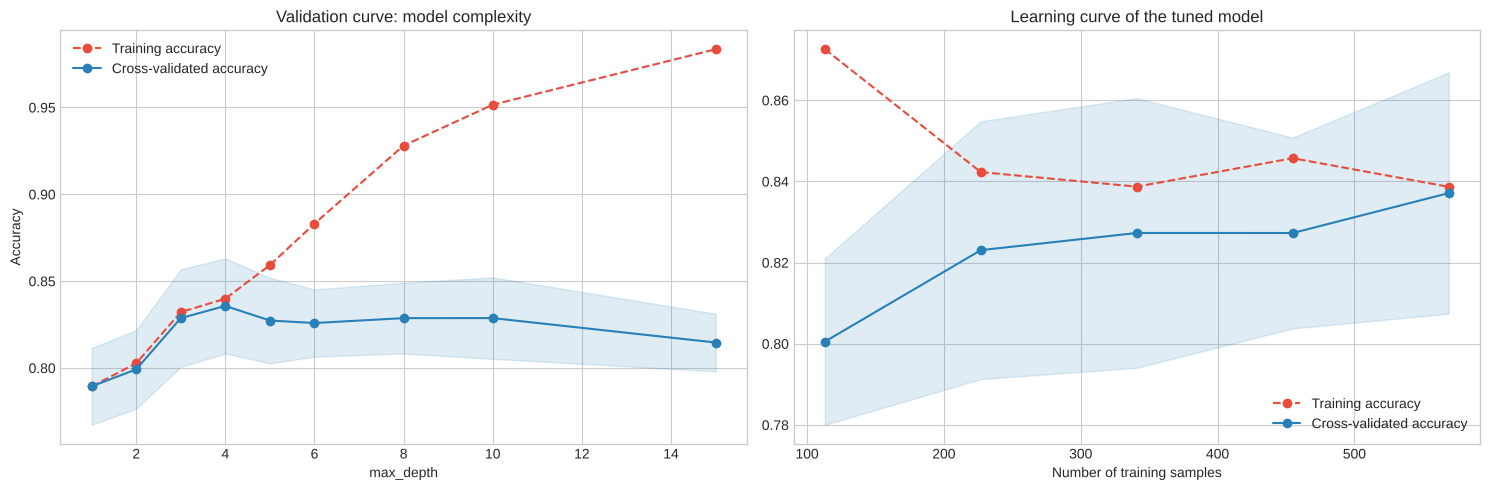

max_depth,1,2,3,4,5,6,8,10,15
train,0.789,0.803,0.832,0.840,0.859,0.883,0.928,0.952,0.983
validation,0.789,0.799,0.829,0.836,0.827,0.826,0.829,0.829,0.815


In [10]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15]
train_sc, val_sc = validation_curve(rf_pipe, X_train, y_train, param_name="clf__max_depth", param_range=depths,
                                    cv=cv5, scoring="accuracy", n_jobs=-1)

best_rf = searches["Grid search"].best_estimator_
sizes, lc_train, lc_val = learning_curve(best_rf, X_train, y_train, cv=cv5, train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], n_jobs=-1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(depths, train_sc.mean(1), "o--", color="#e74c3c", label="Training accuracy")
axes[0].plot(depths, val_sc.mean(1), "o-", color="#2980b9", label="Cross-validated accuracy")
axes[0].fill_between(depths, val_sc.mean(1) - val_sc.std(1), val_sc.mean(1) + val_sc.std(1), color="#2980b9", alpha=0.15)
axes[0].set_xlabel("max_depth"); axes[0].set_ylabel("Accuracy"); axes[0].set_title("Validation curve: model complexity"); axes[0].legend()

axes[1].plot(sizes, lc_train.mean(1), "o--", color="#e74c3c", label="Training accuracy")
axes[1].plot(sizes, lc_val.mean(1), "o-", color="#2980b9", label="Cross-validated accuracy")
axes[1].fill_between(sizes, lc_val.mean(1) - lc_val.std(1), lc_val.mean(1) + lc_val.std(1), color="#2980b9", alpha=0.15)
axes[1].set_xlabel("Number of training samples"); axes[1].set_title("Learning curve of the tuned model"); axes[1].legend()
plt.tight_layout()
plt.savefig("images/05_validation_and_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

display(pd.DataFrame({"train": train_sc.mean(1), "validation": val_sc.mean(1)}, index=depths).rename_axis("max_depth").round(3).T)

### 📝 Observations (curves)
- **Validation curve:** training accuracy climbs from 0.789 (depth 1) to **0.983 (depth 15)**, while cross-validated accuracy **peaks at depth 4 (0.836)** and then drifts down to 0.815. Deeper trees memorise the training passengers: classic **overfitting**
- **Learning curve:** with more data the training accuracy falls (0.873 → 0.839) and the validation accuracy rises (0.801 → 0.837); the two curves **meet at about 0.84**. The tuned model has stopped being limited by variance, so **more rows of the same kind would add little**; better features would help more

## 🧪 Step 7: Nested Cross-Validation: The Honest Estimate
The best CV score found by a search is **optimistic**: we picked the winner *because* it scored best on those same folds (**selection bias**).
**Nested CV** wraps the whole search in an outer loop: each outer fold runs its own inner search on the outer-training data and is scored on data the search never saw.

Outer-fold accuracies: [0.797 0.818 0.859 0.803 0.782]
Nested CV accuracy     : 0.8118  (± 0.0264)
Search's own best score: 0.8371   <- optimistic
Selection bias         : +0.0253


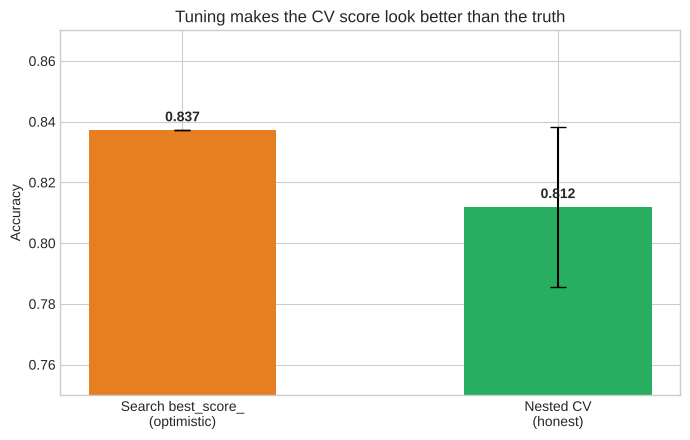

In [11]:
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

inner_search = RandomizedSearchCV(rf_pipe, param_dist, n_iter=10, cv=inner_cv, scoring="accuracy",
                                  random_state=RANDOM_STATE, n_jobs=-1)
nested_scores = cross_val_score(inner_search, X_train, y_train, cv=outer_cv, scoring="accuracy")

optimistic = searches["Random search"].best_score_
print("Outer-fold accuracies:", nested_scores.round(3))
print(f"Nested CV accuracy     : {nested_scores.mean():.4f}  (± {nested_scores.std():.4f})")
print(f"Search's own best score: {optimistic:.4f}   <- optimistic")
print(f"Selection bias         : {optimistic - nested_scores.mean():+.4f}")

plt.figure(figsize=(7, 4.5))
bars = plt.bar(["Search best_score_\n(optimistic)", "Nested CV\n(honest)"], [optimistic, nested_scores.mean()], color=["#e67e22", "#27ae60"], width=0.5,
               yerr=[0, nested_scores.std()], capsize=6)
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.003, f"{b.get_height():.3f}", ha="center", fontweight="bold")
plt.ylim(0.75, 0.87); plt.ylabel("Accuracy"); plt.title("Tuning makes the CV score look better than the truth")
plt.tight_layout()
plt.savefig("images/06_nested_cv.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (nested CV)
- The search reports **0.837**, but nested CV, which scores the *whole procedure* (tune, then predict unseen folds), gives **0.812 (± 0.026)**: a **2.5 point selection bias**
- Compare with the **untuned** random forest (CV ≈ 0.813): once the bias is removed, **tuning bought essentially nothing** here
- Rule of thumb: report the nested (or held-out test) score, never the `best_score_` of the search

## 🏁 Step 8: Final Comparison on the Held-Out Test Set

,Test accuracy,Test ROC-AUC,Test F1 (survived)
Model,,,
Logistic Regression (default),0.8324,0.8726,0.7761
Random Forest (default),0.8156,0.8291,0.7591
Random Forest (grid),0.7933,0.8427,0.7132
Random Forest (random),0.7933,0.8479,0.7132
Random Forest (halving),0.7933,0.8397,0.7132
Gradient Boosting (random),0.7933,0.8375,0.7132


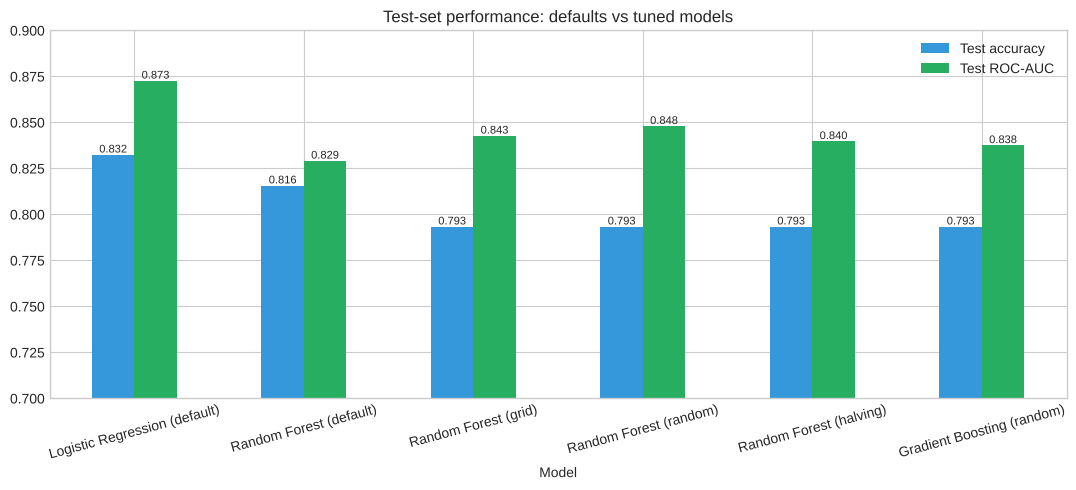

Gradient boosting search: best CV = 0.8371


In [12]:
gb_pipe = Pipeline([("prep", make_preprocessor(False)), ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE))])
gb_search = RandomizedSearchCV(gb_pipe, {"clf__n_estimators": randint(50, 300), "clf__learning_rate": uniform(0.01, 0.3),
                                         "clf__max_depth": [2, 3, 4], "clf__subsample": [0.6, 0.8, 1.0]},
                               n_iter=15, cv=cv5, n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)

final_models = {
    "Logistic Regression (default)": models["Logistic Regression"],
    "Random Forest (default)": models["Random Forest"],
    "Random Forest (grid)": searches["Grid search"].best_estimator_,
    "Random Forest (random)": searches["Random search"].best_estimator_,
    "Random Forest (halving)": searches["Halving search"].best_estimator_,
    "Gradient Boosting (random)": gb_search.best_estimator_,
}
rows = []
for name, model in final_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({"Model": name, "Test accuracy": accuracy_score(y_test, pred),
                 "Test ROC-AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
                 "Test F1 (survived)": f1_score(y_test, pred)})
test_table = pd.DataFrame(rows).set_index("Model").round(4)
display(test_table)

ax = test_table[["Test accuracy", "Test ROC-AUC"]].plot(kind="bar", figsize=(11, 5), color=["#3498db", "#27ae60"], rot=15)
ax.set_ylim(0.7, 0.9); ax.set_title("Test-set performance: defaults vs tuned models")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.savefig("images/07_test_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Gradient boosting search: best CV =", round(gb_search.best_score_, 4))

### 📝 Observations (test set)
| Model | Test accuracy | Test ROC-AUC | Test F1 |
|---|---|---|---|
| **Logistic Regression (default)** | **0.8324** | **0.8726** | **0.7761** |
| Random Forest (default) | 0.8156 | 0.8291 | 0.7591 |
| Random Forest (grid) | 0.7933 | 0.8427 | 0.7132 |
| Random Forest (random) | 0.7933 | 0.8479 | 0.7132 |
| Random Forest (halving) | 0.7933 | 0.8397 | 0.7132 |
| Gradient Boosting (random) | 0.7933 | 0.8375 | 0.7132 |

- ⚠️ **The tuned models did not beat the defaults on the test set.** Their **CV accuracy rose** (0.813 → 0.837) but **test accuracy fell** (0.816 → 0.793): the optimism of the search score (selection bias) in action
- They did improve the **ROC-AUC** (0.829 → 0.84 to 0.85), i.e. how well they *rank* passengers, but at the default 0.5 cut-off the shallow trees predict fewer survivors, so accuracy and F1 dropped
- Keep the scale in mind: the test set has only **179 passengers**, so 0.793 vs 0.816 is a difference of **4 passengers** and 0.832 vs 0.793 is **7 passengers** (the standard error is about ± 3 points). Do not read "tuning hurts"; read **"tuning did not help measurably"**
- The **untuned logistic regression is the best test model** (accuracy 0.832, AUC 0.873): the simplest model wins again, exactly as the baseline CV suggested

In [13]:
# Save the complete pipeline (imputers + encoder + model) as ONE file, reload it and predict a new passenger from RAW inputs
final_pipeline = searches["Grid search"].best_estimator_
joblib.dump(final_pipeline, "titanic_pipeline.joblib")
loaded = joblib.load("titanic_pipeline.joblib")

def predict_passenger(name, pclass, sex, age, sibsp, parch, fare, embarked, cabin=None):
    raw = pd.DataFrame([{"Name": name, "Pclass": pclass, "Sex": sex, "Age": age, "SibSp": sibsp, "Parch": parch,
                         "Fare": fare, "Cabin": cabin, "Embarked": embarked}])
    features = add_features(raw)
    features[categorical_cols] = features[categorical_cols].astype(object)
    return loaded.predict_proba(features)[0, 1]

examples = [
    ("Smith, Mrs. Anna", 1, "female", 35, 1, 0, 80.0, "S", "C85"),
    ("Brown, Mr. John", 3, "male", 25, 0, 0, 7.9, "S", None),
    ("Lee, Master. Tom", 2, "male", 6, 1, 1, 26.0, "S", None),
]
for ex in examples:
    print(f"P(survive) = {predict_passenger(*ex):.1%}   | {ex[0]}, class {ex[1]}, {ex[2]}, age {ex[3]}")

P(survive) = 95.7%   | Smith, Mrs. Anna, class 1, female, age 35
P(survive) = 10.3%   | Brown, Mr. John, class 3, male, age 25
P(survive) = 49.1%   | Lee, Master. Tom, class 2, male, age 6


## ✅ Conclusion
- **Pipelines are non-negotiable:** every learned preprocessing step must live inside the cross-validation loop. A leaky procedure turned pure noise into "82% accuracy" (true: 53%)
- **Cross-validation is noisy:** single folds ranged 0.78 to 0.84 and different shuffles moved the mean by ± 0.01, so differences smaller than ~1 point are not real
- **Grid, Random and Halving search** all found settings with a CV accuracy of 0.83 to 0.84 (shallow trees, mild regularisation), and the validation curve shows why: depth ≈ 4 is the sweet spot, deeper trees overfit
- **The search score is optimistic:** nested CV gave **0.812** vs the search's 0.837: tuning added essentially nothing over the default forest (≈ 0.813), and a plain logistic regression (0.829) was already as good
- On this small dataset the realistic ceiling is about **0.81 to 0.83**; improvement would need better features or more data, not more tuning
- On the held-out test set the **untuned logistic regression was best** (accuracy 0.832, AUC 0.873) while all tuned forests and boosting scored 0.793 accuracy (AUC 0.84 to 0.85): the tuned models were *not* better
- The whole model, preprocessing included, is saved as **one `.joblib` file** and predicts directly from raw passenger fields

## 🎤 Interview Questions: Short Answers
1. **Parameters vs hyperparameters?** Parameters are learned from data during training (weights, split thresholds). Hyperparameters are set *before* training and control the learning process or model complexity (tree depth, `C`, learning rate, `k`).
2. **Grid search vs random search?** Grid search tries every combination of a fixed grid (exhaustive, cost multiplies with every added parameter). Random search samples combinations from distributions: for the same budget it tries many more distinct values of each parameter, and usually finds comparable or better settings because only a few hyperparameters really matter.
3. **What is successive halving?** Start with many candidates on a small resource (a few samples), keep the best 1/factor, give them more resource, repeat. It spends most of the budget on promising candidates (`HalvingRandomSearchCV`).
4. **What is k-fold cross-validation, and why stratified?** Split the training data into k parts; train on k-1, validate on the remaining one, rotate and average. Stratified folds keep the class proportions in every fold, which matters for imbalanced data.
5. **What is data leakage and how do Pipelines prevent it?** Leakage is information from validation / test data influencing training (here, selecting features on all labels turned noise into 82% accuracy). A Pipeline re-fits every learned step (imputer, scaler, selector, encoder) on the training fold only.
6. **What is nested cross-validation and why use it?** An outer CV loop evaluates a whole "tune + fit" procedure, with an inner CV loop doing the tuning. It removes the selection bias of reporting the best search score (0.837 vs honest 0.812 here).
7. **Validation set vs test set?** The validation data (or CV folds) is used to *choose* hyperparameters; the test set is touched once at the end for an unbiased final estimate. Tuning on the test set turns it into a validation set.
8. **How do you choose the scoring metric for tuning?** Match the business goal: accuracy for balanced classes, F1 / recall / PR-AUC for imbalanced ones, ROC-AUC for ranking, RMSE/MAE for regression. Optimising the wrong metric yields the wrong model.
9. **How do you detect overfitting during tuning?** Compare training and validation scores along a validation curve; a growing gap (here training 0.98 vs validation 0.82 at depth 15) signals overfitting. Learning curves show whether more data would help.
10. **How many folds should you use?** 5 or 10 is typical: more folds lower the bias but cost more time and give correlated estimates; repeated k-fold reduces the noise from a single shuffle, which matters on small data like this.
11. **When is Bayesian optimisation better than random search?** When each evaluation is expensive: it models the score surface and picks promising points (tools: Optuna, scikit-optimize, Hyperopt). For cheap models random search is often enough.
12. **Why scale features inside the pipeline only for some models?** Distance and gradient-based models (KNN, logistic regression, SVM) are scale-sensitive; tree ensembles are not. Putting the scaler in the pipeline guarantees it is fitted on training folds only.